# Name That LLM — EDA

Exploring `data/train.csv`: 18 candidate models, balanced-accuracy scoring, passages 40-250 words.
Goal: understand class balance, the prompt/model pairing structure, text-length behavior, and any
cheap stylistic fingerprints (punctuation, function words) before building features.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

df = pd.read_csv('../data/train.csv')
df['n_words'] = df['text'].str.split().str.len()
df['n_chars'] = df['text'].str.len()
LABELS = sorted(df['model'].unique())
print(df.shape)
df.head()

(2699, 6)


,id,prompt_id,text,model,n_words,n_chars
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,192,1143
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,65,518
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,77,474
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra,220,1724
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash,97,541


## 1. Class balance
Balanced accuracy weights every model equally, so check how close to equal the train rows already are.

model
claude-fable-5            149
claude-opus-4-6           150
claude-opus-4-8           150
claude-opus-5             150
claude-sonnet-5           150
gemini-3.1-pro-preview    150
gemini-3.6-flash          150
gemini-3.7-flash          150
gemini-3.8-flash          150
glm-5.3                   150
glm-5.3-flash             150
gpt-5.5                   150
gpt-5.6-luna              150
gpt-5.6-sol               150
gpt-5.6-terra             150
gpt-6-astra               150
kimi-k3                   150
qwen3.8-max               150
Name: count, dtype: int64

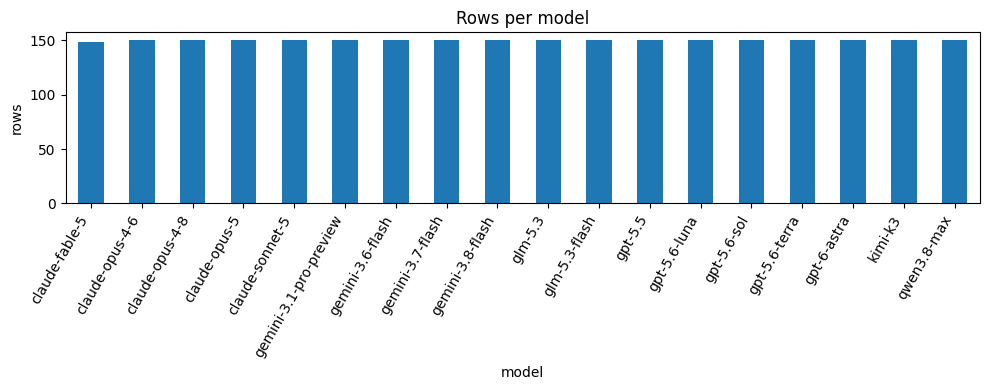

In [2]:
counts = df['model'].value_counts().sort_index()
display(counts)

fig, ax = plt.subplots(figsize=(10, 4))
counts.plot.bar(ax=ax)
ax.set_ylabel('rows')
ax.set_title('Rows per model')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

## 2. Prompt / model pairing structure
`prompt_id` looks shared across models (every model answering the same ~150 prompts). If so,
train/validation splits MUST be grouped by `prompt_id`, or a model will "memorize" topic
instead of learning style — and CV will look better than true held-out performance.

In [3]:
n_prompts = df['prompt_id'].nunique()
per_prompt = df.groupby('prompt_id')['model'].nunique()
per_prompt_model_counts = df.groupby('prompt_id').size()
print('unique prompts:', n_prompts)
print('models per prompt - distribution:')
display(per_prompt.value_counts().sort_index())

# which (prompt, model) pairs are missing from a fully-crossed design?
full_grid = pd.MultiIndex.from_product([df['prompt_id'].unique(), LABELS], names=['prompt_id', 'model'])
present = set(map(tuple, df[['prompt_id', 'model']].values))
missing = [pm for pm in full_grid if pm not in present]
print(f'missing (prompt_id, model) pairs out of {len(full_grid)}: {len(missing)}')
missing

unique prompts: 150
models per prompt - distribution:


model
17      1
18    149
Name: count, dtype: int64

missing (prompt_id, model) pairs out of 2700: 1


[('p002', 'claude-fable-5')]

In [4]:
# duplicate prompt_id+model rows?
dupe_mask = df.duplicated(subset=['prompt_id', 'model'], keep=False)
print('duplicated (prompt_id, model) rows:', int(dupe_mask.sum()))

# any exact duplicate text (possible copy/leak)?
print('exact duplicate texts:', int(df['text'].duplicated().sum()))
print('null texts:', int(df['text'].isna().sum()))

duplicated (prompt_id, model) rows: 0
exact duplicate texts: 0
null texts: 0


## 3. Text length behavior
Passage length is randomized 40-250 words per the README, but models may still differ in their
*typical* length, variance, or how tightly they hit the requested range — all of which a naive
model could latch onto as a shortcut (and which may NOT transfer to the hidden test distribution,
so treat any length-based signal cautiously).

,mean,std,median,min,max
model,,,,,
gemini-3.8-flash,100.680000,52.803462,84.0,41,238
kimi-k3,107.366667,53.713185,89.0,39,239
gemini-3.6-flash,111.153333,54.140971,95.5,40,238
glm-5.3,110.340000,56.811691,96.0,36,244
qwen3.8-max,108.346667,56.781931,98.5,39,265
claude-opus-4-6,115.146667,60.873881,98.5,42,274
claude-sonnet-5,120.046667,64.276285,99.5,39,267
claude-fable-5,112.496644,58.178386,100.0,39,252
gpt-5.6-terra,113.260000,54.456365,100.5,43,239


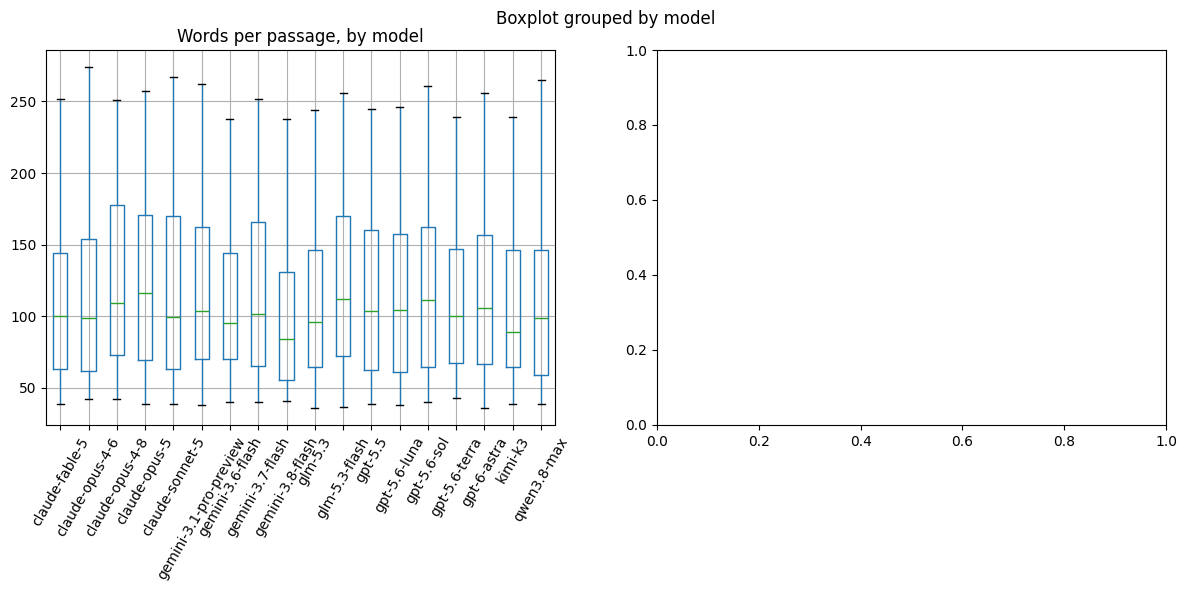

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = df.groupby('model')['n_words'].median().sort_values().index
df.boxplot(column='n_words', by='model', ax=axes[0], rot=60)
axes[0].set_title('Words per passage, by model')
axes[0].set_xlabel('')
df.groupby('model')['n_words'].agg(['mean', 'std', 'median', 'min', 'max']).loc[order]

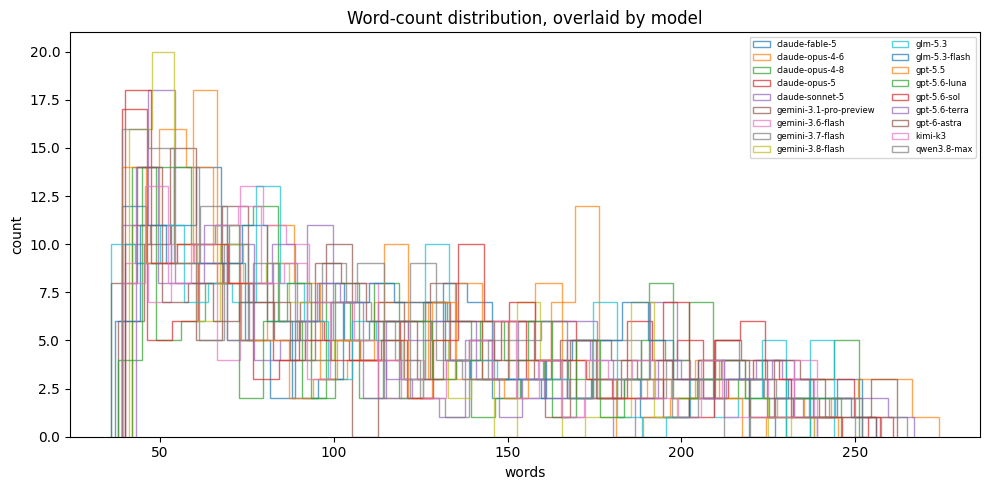

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for m in LABELS:
    ax.hist(df.loc[df['model'] == m, 'n_words'], bins=30, histtype='step', label=m, alpha=0.7)
ax.set_xlabel('words')
ax.set_ylabel('count')
ax.set_title('Word-count distribution, overlaid by model')
ax.legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

## 4. Same-prompt, different-model comparison
Since most prompts are answered by all 18 models, print a few prompt groups side by side to get
an intuitive feel for what actually distinguishes models on identical topics/instructions.

In [7]:
sample_prompt = df['prompt_id'].value_counts().index[0]
sub = df[df['prompt_id'] == sample_prompt][['model', 'text']]
for _, row in sub.sample(min(5, len(sub)), random_state=0).iterrows():
    print(f"--- {row['model']} ---")
    print(row['text'][:400])
    print()

--- gemini-3.7-flash ---
When a language dies, an entire universe folds inward, erasing unmapped constellations of thought. Unique grammars of starlight, ancestral understandings of time's circular breath, and intimate dialogues with the wilderness vanish forever, reducing the cosmos to a flatter, emptier silence.

--- gpt-6-astra ---
When a language dies, the stars lose one of their names for home. Gone are the verbs that let rivers remember, the kinships between moonlight and mourning, the grammar that placed humans among, not above, other beings. The cosmos remains, but one way of belonging vanishes.

--- claude-opus-4-6 ---
When a language dies, it carries into silence not merely vocabulary but entire architectures of thought—constellations named for forgotten myths, verb tenses that encoded the speaker's relationship to starlight, grammatical structures that made no distinction between the observer and the observed sky. Some languages possessed dozens of words for darkness, each d

## 5. Punctuation / orthographic fingerprints
A prior public notebook claimed hard rules like "Claude & GLM never use curly quotes" and
"Gemini rarely uses >=2 em-dashes." Check those claims directly on this train set rather than
trusting them — these are exactly the kind of brittle, sampling-setting artifacts that may not
hold on the hidden test set.

In [8]:
def has_curly_quote(t):
    return any(c in t for c in ('\u2019', '\u201c', '\u201d'))


def count_em_dash(t):
    return t.count('\u2014')


feat = pd.DataFrame({
    'model': df['model'],
    'has_curly_quote': df['text'].apply(has_curly_quote),
    'em_dash_count': df['text'].apply(count_em_dash),
    'has_2plus_em_dash': df['text'].apply(count_em_dash) >= 2,
})

curly_rate = feat.groupby('model')['has_curly_quote'].mean().sort_values(ascending=False)
print('Curly-quote usage rate by model:')
display(curly_rate.to_frame('rate'))

em_rate = feat.groupby('model')['has_2plus_em_dash'].mean().sort_values(ascending=False)
print('\n>=2 em-dash usage rate by model:')
display(em_rate.to_frame('rate'))

Curly-quote usage rate by model:


,rate
model,
gpt-5.6-sol,0.580000
gpt-5.6-luna,0.546667
gpt-6-astra,0.486667
gpt-5.6-terra,0.480000
gpt-5.5,0.466667
kimi-k3,0.373333
gemini-3.7-flash,0.306667
qwen3.8-max,0.293333
gemini-3.8-flash,0.260000



>=2 em-dash usage rate by model:


,rate
model,
glm-5.3-flash,0.513333
glm-5.3,0.513333
claude-opus-5,0.460000
claude-fable-5,0.402685
claude-sonnet-5,0.353333
claude-opus-4-6,0.346667
claude-opus-4-8,0.286667
kimi-k3,0.260000
gpt-5.6-terra,0.140000


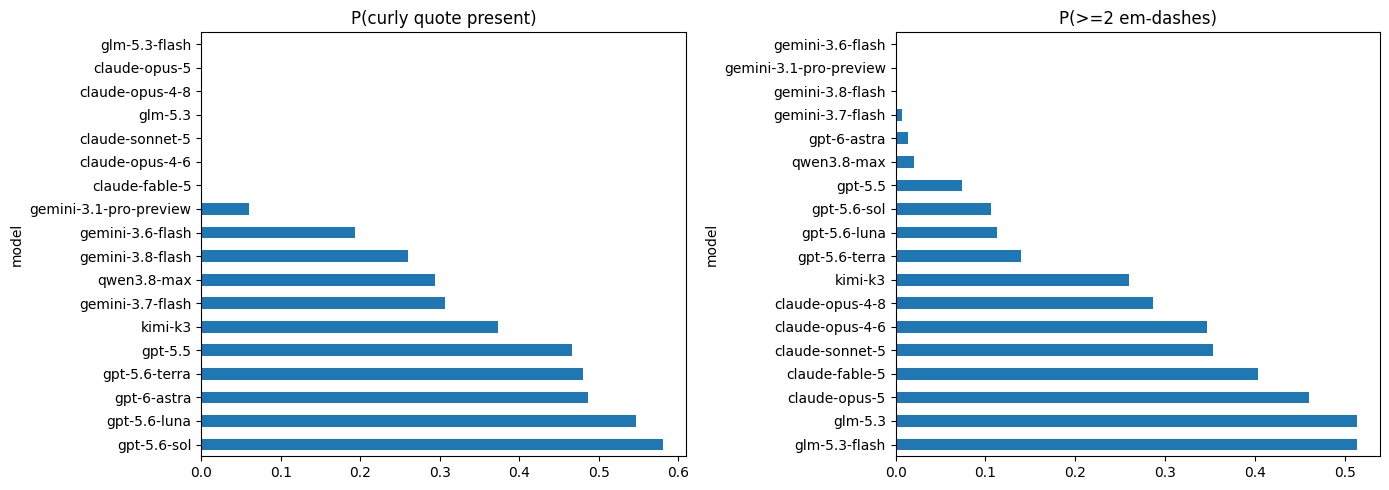

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
curly_rate.plot.barh(ax=axes[0])
axes[0].set_title('P(curly quote present)')
em_rate.plot.barh(ax=axes[1])
axes[1].set_title('P(>=2 em-dashes)')
plt.tight_layout()
plt.show()

## 6. Other quick stylometric signals
Sentence length, exclamation/question usage, average word length, lexical diversity —
cheap per-passage features that feed a LightGBM/LinearSVC stylometric head.

In [10]:
SENT = re.compile(r'(?<=[.!?])\s+')
WORD = re.compile(r"[A-Za-z\u2019']+")


def stylo(t):
    words = WORD.findall(t)
    nw = max(len(words), 1)
    sents = [s for s in SENT.split(t.strip()) if s]
    sl = [len(WORD.findall(s)) for s in sents] or [0]
    wl = [len(w) for w in words] or [0]
    return pd.Series({
        'n_sentences': len(sents),
        'mean_sent_len': np.mean(sl),
        'mean_word_len': np.mean(wl),
        'lexical_diversity': len(set(w.lower() for w in words)) / nw,
        'comma_rate': t.count(',') / nw,
        'semicolon_rate': t.count(';') / nw,
        'exclaim_rate': t.count('!') / nw,
        'question_rate': t.count('?') / nw,
    })


stylo_feats = df['text'].apply(stylo)
stylo_df = pd.concat([df[['model']], stylo_feats], axis=1)
stylo_df.groupby('model').mean().round(4)

,n_sentences,mean_sent_len,mean_word_len,lexical_diversity,comma_rate,semicolon_rate,exclaim_rate,question_rate
model,,,,,,,,
claude-fable-5,4.7114,24.5884,5.2973,0.8124,0.0915,0.0035,0.0000,0.0004
claude-opus-4-6,4.2733,27.4958,5.5874,0.8151,0.0775,0.0012,0.0000,0.0003
claude-opus-4-8,5.0733,24.2185,5.3996,0.8021,0.0949,0.0019,0.0000,0.0004
claude-opus-5,5.1600,24.1002,5.0248,0.7822,0.0836,0.0058,0.0002,0.0005
claude-sonnet-5,4.5533,26.7153,5.5932,0.8231,0.0961,0.0023,0.0001,0.0001
gemini-3.1-pro-preview,5.7667,20.2763,5.4952,0.8043,0.0756,0.0016,0.0001,0.0005
gemini-3.6-flash,4.5933,24.7124,5.7099,0.8277,0.0836,0.0020,0.0000,0.0004
gemini-3.7-flash,4.8067,23.9339,5.9279,0.8407,0.0825,0.0020,0.0000,0.0003
gemini-3.8-flash,4.4200,22.7701,5.8869,0.8597,0.0852,0.0028,0.0000,0.0003


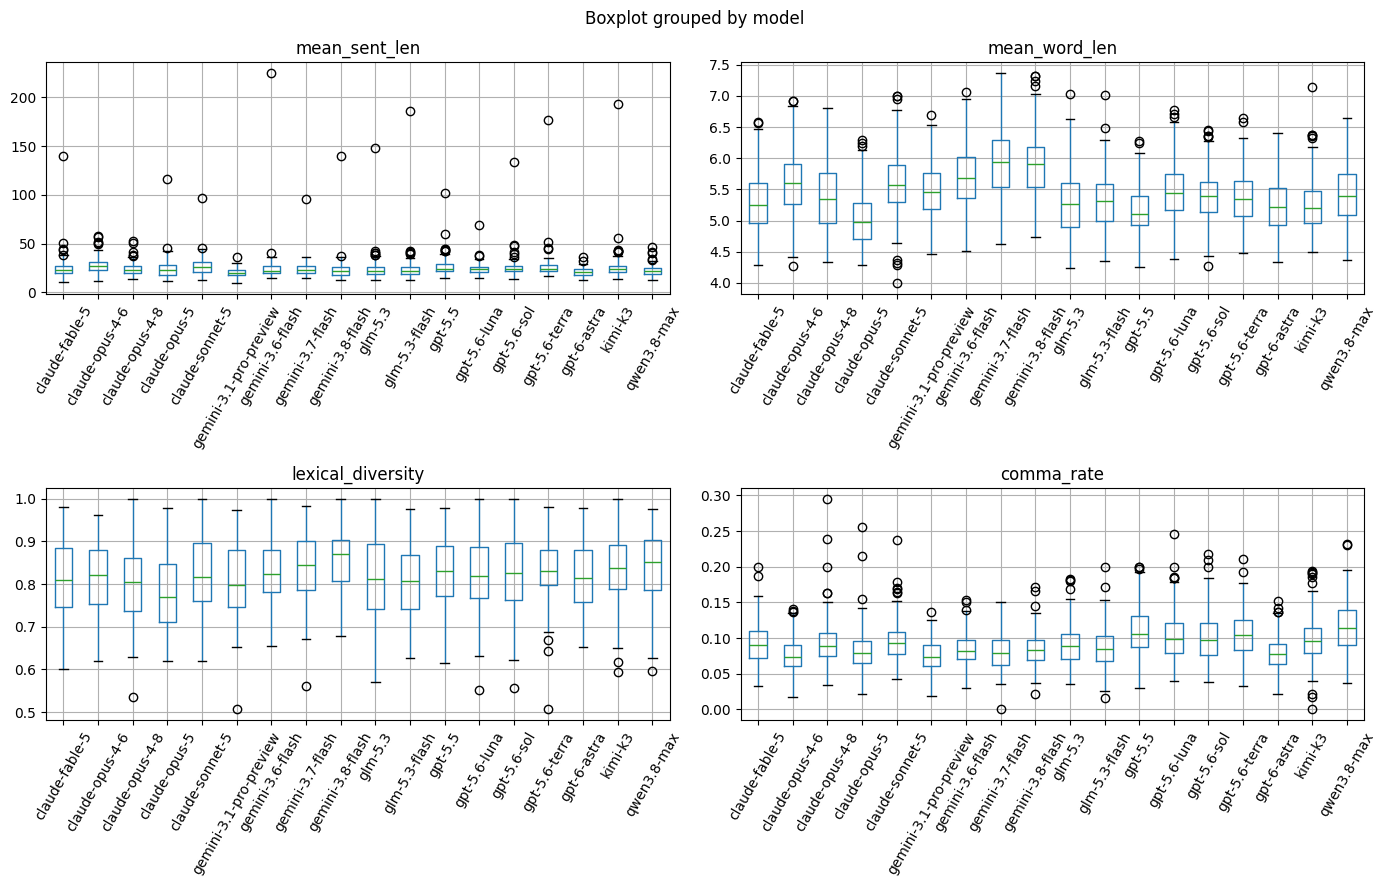

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ['mean_sent_len', 'mean_word_len', 'lexical_diversity', 'comma_rate']):
    order = stylo_df.groupby('model')[col].median().sort_values().index
    stylo_df.boxplot(column=col, by='model', ax=ax, rot=60)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

## 7. Top distinguishing words per model (chi2 on word counts)
Quick signal check: which unigrams are most associated with each model, via a chi-square test
on a CountVectorizer matrix. Gives a sense of whether lexical choice alone carries real signal
beyond generic topic words (stopwords removed).

In [12]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words='english', min_df=5, max_features=5000)
X = cv.fit_transform(df['text'])
vocab = np.array(cv.get_feature_names_out())

y = df['model'].values
top_words = {}
for m in LABELS:
    yb = (y == m).astype(int)
    # chi2 per model-vs-rest
    from sklearn.feature_selection import chi2
    scores, _ = chi2(X, yb)
    top_idx = np.argsort(scores)[::-1][:12]
    top_words[m] = list(vocab[top_idx])

pd.DataFrame(top_words).T

,0,1,2,3,4,5,6,7,8,9,10,11
claude-fable-5,insisting,shorter,complete,told,zoom,conversation,lucky,charts,difference,confirmed,thinking,suggests
claude-opus-4-6,comfortable,roughly,traverse,deeply,ve,underlying,civilization,percent,doesn,potentially,emerges,architectures
claude-opus-4-8,quietly,glimpse,illuminate,immensity,retreat,isn,lifetime,utterly,famously,thousand,churn,author
claude-opus-5,meant,rumor,thing,woman,arrives,arithmetic,arriving,million,thousand,goes,happen,right
claude-sonnet-5,isn,atop,requires,igniting,infinitesimal,mid,entirely,term,experts,actually,stability,potentially
gemini-3.1-pro-preview,profound,absolute,ultimate,biological,microscopic,relentless,jagged,sprawling,entirely,actively,chaotic,bizarre
gemini-3.6-flash,dynamic,expanse,breathtaking,void,mathematical,severe,delicate,microscopic,unyielding,vibrant,global,terrifying
gemini-3.7-flash,profound,fundamentally,expanse,standard,intellect,biological,intricate,perpetual,consequently,primordial,structural,subjective
gemini-3.8-flash,tempest,permanently,enduring,flora,transforming,agonizing,abyss,ferocious,ethereal,majesty,effortlessly,subterranean
glm-5.3,wire,balls,believe,ball,billion,fragments,forgive,hangs,vent,shrink,really,way


## 8. Summary

- Classes are perfectly balanced (150/model, 149 for `claude-fable-5`), so train-set accuracy and
  balanced accuracy coincide here — but the hidden test set mix is explicitly *not* balanced, so a
  model must still get minority models right, not just the majority ones.
- Prompts are (almost) fully crossed with models — this is a paired design, so **any CV must be
  grouped by `prompt_id`**, otherwise a model partially learns topic/content instead of style and
  CV will overstate real generalization to the hidden test set's unseen prompts.
- Length distributions differ across models but are constrained to the same 40-250 word window by
  design — treat length-based features as a weak, possibly non-transferable signal.
- Punctuation habits (curly quotes, em-dash usage) show visible skew across providers, but the
  rates should be read as soft, noisy signal, not hard rules — baking in a hard "never does X"
  rule risks breaking on hidden-test passages that happen to violate it.
- Lexical chi2 analysis shows real per-model word preferences beyond generic topic words,
  supporting a word+char n-gram model as a solid baseline signal source.
